# 08 — Clasificación: Riesgo de Reseña Negativa
## DataSmart Olist · Rama `feature/classification`

**Pregunta de negocio:** ¿Qué pedidos tienen riesgo de recibir una reseña negativa?

**Variable objetivo:** `review_negativa = 1` si `review_score <= 2` (1–2 estrellas), `0` en otro caso.

### Hallazgos del EDA que guían el módulo
1. **Desbalance:** ~14.7% de las reseñas son negativas → no sirve *accuracy*; se priorizan PR-AUC, recall, F1 y balanced accuracy.
2. **La entrega manda:** las entregas tardías tienen 54.07% de negativas frente a 9.22% de las puntuales → las variables logísticas son las candidatas más fuertes.
3. **Churn no observable:** con 3.06% de recompra, la reseña negativa es el mejor indicador disponible de insatisfacción (ver limitaciones de `02_preparation`).

### Momento de predicción (decisión de diseño clave)
Olist envía la encuesta de satisfacción (`review_creation_date`) **al día siguiente de la entrega o, si el pedido no llegó, en la fecha estimada**. Esa fecha la fija Olist, no el cliente, así que es un momento operativo conocido de antemano. El modelo principal predice **en el instante en que se envía la encuesta**, antes de que el cliente responda; eso permite una acción proactiva (contacto de postventa, cupón, seguimiento del envío) sobre los pedidos de mayor riesgo. Consecuencias:
- Las variables logísticas se calculan **con lo observado hasta esa fecha**: si el pedido ya llegó se conocen los días de entrega y de retraso; si sigue pendiente solo se sabe que está pendiente y cuántos días lleva vencida la promesa.
- Se excluye todo lo que proviene de la respuesta del cliente (puntaje, comentario, título, fecha de respuesta) para evitar *data leakage*.
- Como escenario complementario se entrena un modelo **al momento de la compra** (sin información logística) sobre los mismos pedidos, para medir cuánto del riesgo es anticipable desde el checkout.

> Una primera versión predecía "al entregar" y excluía los pedidos con reseña anterior a la entrega. Eso eliminaba justamente los pedidos atrasados (≈73% de negativas) y dejaba al modelo sin su señal principal; por eso se adoptó el corte en el envío de la encuesta.

### Validación
Partición **temporal**: se entrena con compras hasta mayo-2018 y se evalúa con junio–agosto 2018, imitando el uso real (entrenar con el pasado y predecir el futuro). La selección de modelo y del umbral se hace **solo con el conjunto de entrenamiento** (validación cruzada); el test se usa una sola vez.

## 0. Setup y configuración del entorno

In [1]:
import warnings
warnings.filterwarnings('ignore')

import json
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import jsonschema
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

# Paleta del proyecto DataSmart (misma que 04_clustering)
PALETTE = {
    'bondi': '#0799B6',
    'san_marino': '#4A6EB0',
    'eden': '#114C5F',
    'sinbad': '#9CD2D3',
    'janna': '#F2E6CF',
    'terracota': '#E07B54',
}
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 60)

RANDOM_STATE = 42

# Rutas del repositorio (funciona desde la raíz o desde notebooks/08_classification)
ROOT = Path.cwd().parents[1] if Path.cwd().name == '08_classification' else Path.cwd()
DATA_DIR = ROOT / 'data' / 'raw'
ARTIFACTS_DIR = ROOT / 'artifacts' / 'classification'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f'Raíz del proyecto:    {ROOT}')
print(f'Datos en:             {DATA_DIR}')
print(f'Artefactos destino:   {ARTIFACTS_DIR}')

Raíz del proyecto:    /home/emanuel/olist/repo
Datos en:             /home/emanuel/olist/repo/data/raw
Artefactos destino:   /home/emanuel/olist/repo/artifacts/classification


## 1. Carga de datos crudos

Se usan 9 tablas de Olist. El tablón se construye desde `data/raw/` para que el notebook sea reproducible sin depender de archivos intermedios.

In [2]:
t_inicio = time.time()
leer = lambda nombre, **kw: pd.read_csv(DATA_DIR / nombre, encoding='utf-8-sig', **kw)

orders = leer('olist_orders_dataset.csv', parse_dates=[
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date'])
customers = leer('olist_customers_dataset.csv')
items = leer('olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])
products = leer('olist_products_dataset.csv')
sellers = leer('olist_sellers_dataset.csv')
payments = leer('olist_order_payments_dataset.csv')
reviews = leer('olist_order_reviews_dataset.csv', parse_dates=['review_creation_date', 'review_answer_timestamp'])
geo = leer('olist_geolocation_dataset.csv')
cat_tr = leer('product_category_name_translation.csv')

pd.DataFrame({
    'tabla': ['orders', 'customers', 'items', 'products', 'sellers', 'payments', 'reviews', 'geolocation', 'category_tr'],
    'filas': [len(t) for t in (orders, customers, items, products, sellers, payments, reviews, geo, cat_tr)],
})

,tabla,filas
0,orders,99441
1,customers,99441
2,items,112650
3,products,32951
4,sellers,3095
5,payments,103886
6,reviews,99224
7,geolocation,1000163
8,category_tr,71


## 2. Construcción del tablón analítico (un registro por pedido)

Familias de variables:

| Familia | Variables | Disponible al comprar | Disponible al enviar la encuesta |
|---|---|:-:|:-:|
| Temporal de compra | día de semana, hora, fin de semana | ✓ | ✓ |
| Promesa y aprobación | horas de aprobación, días estimados, días límite de despacho | ✓ | ✓ |
| Composición del pedido | ítems, productos, vendedores, categorías, precio, flete, ratio flete, peso, volumen, fotos, largo de descripción, categoría principal | ✓ | ✓ |
| Pago | medio principal, cuotas, número de medios | ✓ | ✓ |
| Geografía | distancia cliente–vendedor (haversine), mismo estado, estado del cliente, región del vendedor | ✓ | ✓ |
| Ejecución logística observada | pendiente de entrega, días de despacho, despacho vencido, días de transporte, días de entrega, días de retraso, entrega tardía | ✗ | ✓ |

Reglas de preparación heredadas de `02_preparation`: una reseña por pedido (la última respondida), categoría traducida o `sin_categoria`.

In [3]:
REGION = {
    **dict.fromkeys(['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'], 'Norte'),
    **dict.fromkeys(['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'], 'Nordeste'),
    **dict.fromkeys(['DF', 'GO', 'MT', 'MS'], 'Centro-Oeste'),
    **dict.fromkeys(['ES', 'MG', 'RJ', 'SP'], 'Sudeste'),
    **dict.fromkeys(['PR', 'RS', 'SC'], 'Sul'),
}

# Reseñas: una por pedido (la última respondida), como en la preparación de datos
rev = (reviews.sort_values('review_answer_timestamp')
              .drop_duplicates('order_id', keep='last')
              [['order_id', 'review_score', 'review_creation_date']])

# Centroide por prefijo de CEP, descartando coordenadas fuera de Brasil
geo_ok = geo[geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34)]
coords = geo_ok.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()
coords.columns = ['lat', 'lng']

# Productos: categoría en inglés y volumen
prod = products.merge(cat_tr, on='product_category_name', how='left')
prod['categoria'] = prod.product_category_name_english.fillna(prod.product_category_name).fillna('sin_categoria')
prod['volumen_cm3'] = prod.product_length_cm * prod.product_height_cm * prod.product_width_cm

it = (items.merge(prod[['product_id', 'categoria', 'product_weight_g', 'volumen_cm3',
                        'product_photos_qty', 'product_description_lenght']], on='product_id', how='left')
           .merge(sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']], on='seller_id', how='left'))

items_agg = it.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    n_productos=('product_id', 'nunique'),
    n_sellers=('seller_id', 'nunique'),
    n_categorias=('categoria', 'nunique'),
    price_total=('price', 'sum'),
    freight_total=('freight_value', 'sum'),
    peso_total_g=('product_weight_g', 'sum'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_media=('product_photos_qty', 'mean'),
    largo_descripcion_media=('product_description_lenght', 'mean'),
    shipping_limit_date=('shipping_limit_date', 'max'),
    categoria_principal=('categoria', 'first'),
    seller_zip=('seller_zip_code_prefix', 'first'),
    seller_state=('seller_state', 'first'),
).reset_index()
items_agg['seller_lat'] = items_agg.seller_zip.map(coords.lat)
items_agg['seller_lng'] = items_agg.seller_zip.map(coords.lng)

# Pagos: el medio principal es el de mayor monto
pay_agg = payments.groupby('order_id').agg(
    payment_value=('payment_value', 'sum'),
    n_cuotas=('payment_installments', 'max'),
    n_medios_pago=('payment_type', 'nunique'),
).reset_index()
medio_principal = (payments.sort_values('payment_value')
                           .drop_duplicates('order_id', keep='last')[['order_id', 'payment_type']])
pay_agg = pay_agg.merge(medio_principal, on='order_id', how='left')

cust = customers[['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_state']].copy()
cust['cust_lat'] = cust.customer_zip_code_prefix.map(coords.lat)
cust['cust_lng'] = cust.customer_zip_code_prefix.map(coords.lng)

df = (orders.merge(cust, on='customer_id', how='left')
            .merge(items_agg, on='order_id', how='left')
            .merge(pay_agg, on='order_id', how='left')
            .merge(rev, on='order_id', how='left'))
print(f'Tablón: {len(df):,} pedidos (sin multiplicar filas: {len(df) == len(orders)})')

Tablón: 99,441 pedidos (sin multiplicar filas: True)


In [4]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


DIA = pd.Timedelta(days=1)
compra = df.order_purchase_timestamp

# Momento de compra
df['dia_semana'] = compra.dt.dayofweek
df['hora'] = compra.dt.hour
df['fin_de_semana'] = (df.dia_semana >= 5).astype(int)
df['horas_aprobacion'] = ((df.order_approved_at - compra) / pd.Timedelta(hours=1)).clip(lower=0)
df['dias_estimados'] = (df.order_estimated_delivery_date - compra) / DIA
df['dias_limite_despacho'] = (df.shipping_limit_date - compra) / DIA
df['ratio_flete'] = df.freight_total / df.price_total
df['precio_por_item'] = df.price_total / df.n_items
df['distancia_km'] = haversine_km(df.cust_lat, df.cust_lng, df.seller_lat, df.seller_lng)
df['mismo_estado'] = (df.customer_state == df.seller_state).astype(int)
df['region_vendedor'] = df.seller_state.map(REGION)

# Ejecución logística OBSERVADA al enviar la encuesta (T): nada posterior a T entra al modelo
T = df.review_creation_date
entregado_en_T = df.order_delivered_customer_date.dt.normalize() <= T
despachado_en_T = df.order_delivered_carrier_date.dt.normalize() <= T
df['pendiente_en_encuesta'] = (~entregado_en_T).astype(int)
df['dias_despacho'] = ((df.order_delivered_carrier_date - compra) / DIA).where(despachado_en_T)
df['despacho_tardio'] = np.where(despachado_en_T, df.order_delivered_carrier_date > df.shipping_limit_date,
                                 T > df.shipping_limit_date).astype(int)
df['dias_transporte'] = ((df.order_delivered_customer_date - df.order_delivered_carrier_date) / DIA).where(entregado_en_T)
df['dias_entrega'] = ((df.order_delivered_customer_date - compra) / DIA).where(entregado_en_T)
# Entregado: retraso real. Pendiente: días que lleva vencida la promesa al enviar la encuesta
df['dias_retraso'] = ((df.order_delivered_customer_date - df.order_estimated_delivery_date) / DIA).where(
    entregado_en_T, (T - df.order_estimated_delivery_date) / DIA)
df['entrega_tardia'] = (df.dias_retraso > 0).astype(int)
df['estado_en_encuesta'] = np.select([~entregado_en_T, df.dias_retraso > 0], ['Pendiente', 'Entregado tarde'],
                                     'Entregado a tiempo')

# Objetivo
df['review_negativa'] = (df.review_score <= 2).astype(float).where(df.review_score.notna())

df[['dias_estimados', 'dias_entrega', 'dias_retraso', 'distancia_km', 'price_total', 'ratio_flete']].describe().round(2)

,dias_estimados,dias_entrega,dias_retraso,distancia_km,price_total,ratio_flete
count,99441.00,90853.00,98673.00,98172.00,98666.00,98666.00
mean,23.77,11.20,-11.45,601.27,137.75,0.31
std,8.83,6.54,8.46,593.79,210.65,0.32
min,1.65,0.53,-146.02,0.00,0.85,0.00
25%,18.33,6.45,-16.19,185.72,45.90,0.13
50%,23.24,9.90,-11.37,433.71,86.90,0.22
75%,28.42,14.54,-6.20,799.13,149.90,0.38
max,155.14,70.21,34.00,3579.89,13440.00,21.45


### 2.1 Población de estudio

Filtros aplicados en orden (embudo):
1. Pedido con reseña (sin reseña no hay etiqueta).
2. Compras entre ene-2017 y ago-2018 (2016 tiene volumen marginal; después de ago-2018 las reseñas están incompletas).
3. Pedido con ítems registrados.
4. Fechas logísticas coherentes (se descartan los pedidos entregados al cliente antes que al transportista, error de registro según `02_preparation`).

No se filtra por estado del pedido: el estado final (`delivered`, `canceled`...) no se conoce al enviar la encuesta; lo que sí se conoce es si ya llegó o sigue pendiente.

In [5]:
embudo = [('Pedidos totales', len(df))]
base = df[df.review_negativa.notna()]
embudo.append(('Con reseña', len(base)))
base = base[base.order_purchase_timestamp.between('2017-01-01', '2018-08-31 23:59:59')]
embudo.append(('Compras ene-2017 a ago-2018', len(base)))
base = base[base.n_items.notna()]
embudo.append(('Con ítems registrados', len(base)))
base = base[~(base.order_delivered_customer_date < base.order_delivered_carrier_date)]
embudo.append(('Fechas logísticas coherentes  → población de estudio', len(base)))

embudo = pd.DataFrame(embudo, columns=['paso', 'pedidos'])
embudo['% del total'] = (embudo.pedidos / embudo.pedidos.iat[0] * 100).round(2)
embudo

,paso,pedidos,% del total
0,Pedidos totales,99441,100.00
1,Con reseña,98673,99.23
2,Compras ene-2017 a ago-2018,98330,98.88
3,Con ítems registrados,97609,98.16
4,Fechas logísticas coherentes → población de e...,97590,98.14


In [6]:
estado = (base.groupby('estado_en_encuesta').review_negativa.agg(['size', 'mean'])
              .rename(columns={'size': 'pedidos', 'mean': 'tasa_negativas'})
              .reindex(['Entregado a tiempo', 'Entregado tarde', 'Pendiente']))
estado['% de pedidos'] = estado.pedidos / estado.pedidos.sum() * 100
estado.round(4)

,pedidos,tasa_negativas,% de pedidos
estado_en_encuesta,,,
Entregado a tiempo,87671,0.0917,89.8360
Entregado tarde,2901,0.1948,2.9726
Pendiente,7018,0.7402,7.1913


> Los pedidos **pendientes** al enviar la encuesta son pocos, pero concentran la mayor tasa de negativas: el cliente responde la encuesta sin haber recibido su compra. Ese estado es observable por Olist en ese momento, así que es una variable legítima.

## 3. Análisis de la variable objetivo y partición temporal

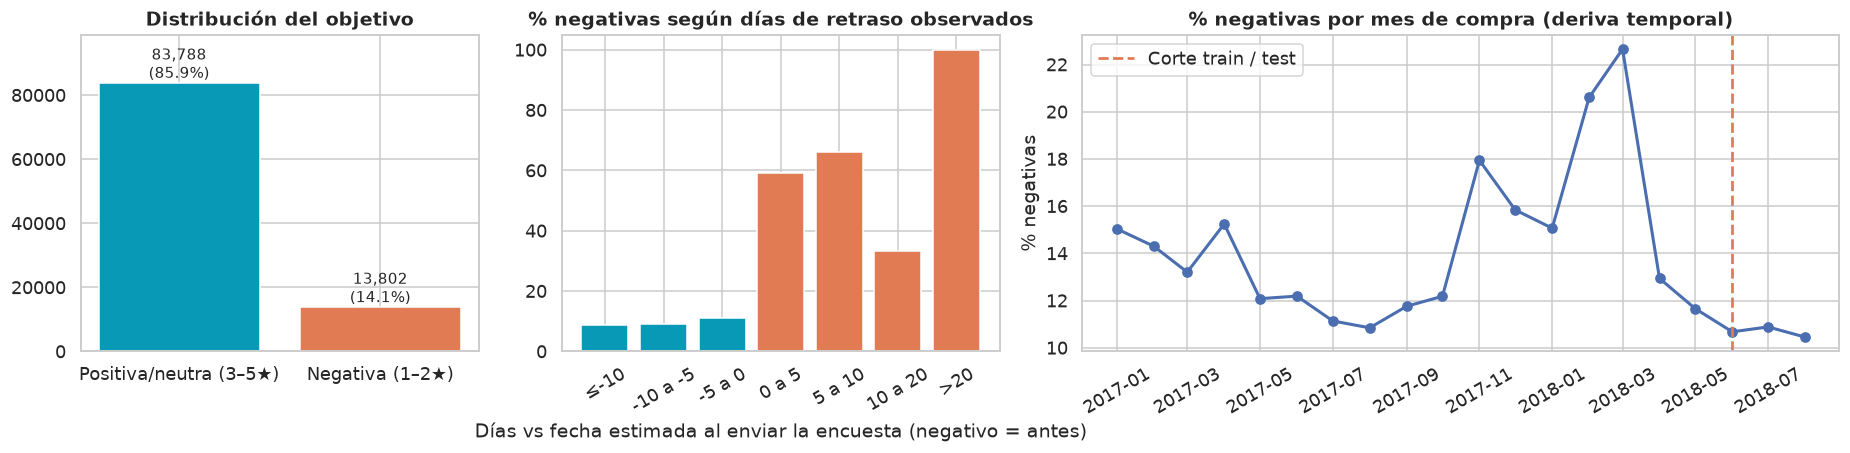

In [7]:
CORTE = pd.Timestamp('2018-06-01')

mensual = (base.assign(mes=base.order_purchase_timestamp.dt.to_period('M').dt.to_timestamp())
               .groupby('mes').agg(pedidos=('review_negativa', 'size'), tasa=('review_negativa', 'mean')))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={'width_ratios': [1, 1.1, 1.9]})

conteo = base.review_negativa.value_counts().sort_index()
axes[0].bar(['Positiva/neutra (3–5★)', 'Negativa (1–2★)'], conteo.values,
            color=[PALETTE['bondi'], PALETTE['terracota']], edgecolor='white')
for i, v in enumerate(conteo.values):
    axes[0].text(i, v, f'{v:,}\n({v / conteo.sum() * 100:.1f}%)', ha='center', va='bottom', fontsize=10)
axes[0].set_title('Distribución del objetivo', fontweight='bold')
axes[0].set_ylim(0, conteo.max() * 1.18)

bins = [-np.inf, -10, -5, 0, 5, 10, 20, np.inf]
etq = ['≤-10', '-10 a -5', '-5 a 0', '0 a 5', '5 a 10', '10 a 20', '>20']
por_retraso = base.groupby(pd.cut(base.dias_retraso, bins, labels=etq), observed=True).review_negativa.mean() * 100
axes[1].bar(por_retraso.index.astype(str), por_retraso.values,
            color=[PALETTE['bondi']] * 3 + [PALETTE['terracota']] * 4, edgecolor='white')
axes[1].set_title('% negativas según días de retraso observados', fontweight='bold')
axes[1].set_xlabel('Días vs fecha estimada al enviar la encuesta (negativo = antes)')
axes[1].tick_params(axis='x', rotation=30)

axes[2].plot(mensual.index, mensual.tasa * 100, 'o-', color=PALETTE['san_marino'], lw=2)
axes[2].axvline(CORTE, color=PALETTE['terracota'], ls='--', lw=1.8, label='Corte train / test')
axes[2].set_title('% negativas por mes de compra (deriva temporal)', fontweight='bold')
axes[2].set_ylabel('% negativas')
axes[2].tick_params(axis='x', rotation=30)
axes[2].legend()
plt.tight_layout()
plt.show()

La tasa de negativas no es estable en el tiempo: sube en nov-2017 (Black Friday) y en feb–mar 2018, coincidiendo con picos de retraso logístico. Por eso una partición aleatoria sería optimista: se valida con el **futuro** (jun–ago 2018).

In [8]:
NUM_COMPRA = [
    'dia_semana', 'hora', 'fin_de_semana', 'horas_aprobacion', 'dias_estimados', 'dias_limite_despacho',
    'n_items', 'n_productos', 'n_sellers', 'n_categorias', 'price_total', 'freight_total', 'ratio_flete',
    'precio_por_item', 'peso_total_g', 'volumen_total_cm3', 'fotos_media', 'largo_descripcion_media',
    'n_cuotas', 'n_medios_pago', 'distancia_km', 'mismo_estado',
]
NUM_ENCUESTA = ['pendiente_en_encuesta', 'dias_despacho', 'despacho_tardio', 'dias_transporte', 'dias_entrega', 'dias_retraso', 'entrega_tardia']
CAT = ['payment_type', 'customer_state', 'region_vendedor', 'categoria_principal']
# Variables asimétricas y no negativas: log1p antes de escalar (ayuda a LR, SVM y NB; neutro para árboles)
LOG_COLS = ['horas_aprobacion', 'price_total', 'freight_total', 'ratio_flete', 'precio_por_item',
            'peso_total_g', 'volumen_total_cm3', 'largo_descripcion_media', 'distancia_km']

NUM = NUM_COMPRA + NUM_ENCUESTA
FEATURES = NUM + CAT
TARGET = 'review_negativa'

train = base[base.order_purchase_timestamp < CORTE]
test = base[base.order_purchase_timestamp >= CORTE]
X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)

pd.DataFrame({
    'conjunto': ['Entrenamiento', 'Prueba'],
    'periodo': [f'{train.order_purchase_timestamp.min():%Y-%m} a {train.order_purchase_timestamp.max():%Y-%m}',
                f'{test.order_purchase_timestamp.min():%Y-%m} a {test.order_purchase_timestamp.max():%Y-%m}'],
    'pedidos': [len(train), len(test)],
    '% negativas': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
    'variables': [len(FEATURES)] * 2,
})

,conjunto,periodo,pedidos,% negativas,variables
0,Entrenamiento,2017-01 a 2018-05,78801,14.97,33
1,Prueba,2018-06 a 2018-08,18789,10.67,33


## 4. Preprocesamiento

Todo va dentro de un `Pipeline` de scikit-learn, así el `fit` de imputadores, escaladores y codificadores ocurre **solo con datos de entrenamiento** en cada fold:
- Numéricas asimétricas: imputación por mediana → `log1p` → `StandardScaler`.
- Resto de numéricas: imputación por mediana → `StandardScaler`.
- Categóricas: imputación por moda → One-Hot (categorías con menos de 300 pedidos se agrupan como *infrequent*).

In [9]:
def construir_preprocesador(num_cols, cat_cols):
    log_cols = [c for c in num_cols if c in LOG_COLS]
    lin_cols = [c for c in num_cols if c not in LOG_COLS]
    return ColumnTransformer([
        ('log', make_pipeline(SimpleImputer(strategy='median'),
                              FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
                              StandardScaler()), log_cols),
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), lin_cols),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=300,
                                            sparse_output=False)), cat_cols),
    ], verbose_feature_names_out=False)


prep = construir_preprocesador(NUM, CAT)
Xt = prep.fit_transform(X_train)
print(f'Matriz transformada: {Xt.shape[0]:,} filas × {Xt.shape[1]} columnas')
print('Ejemplo de columnas One-Hot:', [c for c in prep.get_feature_names_out() if c.startswith('categoria')][:6])

Matriz transformada: 78,801 filas × 90 columnas
Ejemplo de columnas One-Hot: ['categoria_principal_auto', 'categoria_principal_baby', 'categoria_principal_bed_bath_table', 'categoria_principal_books_general_interest', 'categoria_principal_computers_accessories', 'categoria_principal_consoles_games']


## 5. Comparación de modelos (validación cruzada estratificada, 5 folds, sobre el entrenamiento)

| Modelo | Por qué se incluye | Tratamiento del desbalance |
|---|---|---|
| Baseline (prior) | Piso de referencia: PR-AUC = prevalencia | — |
| Regresión Logística | Modelo lineal interpretable | `class_weight='balanced'` |
| Naive Bayes (Gaussiano) | Probabilístico simple, muy rápido | — (prior empírico) |
| SVM lineal | Margen máximo; con 60k+ filas el kernel RBF es inviable (O(n²)), se usa `LinearSVC` calibrado para obtener probabilidades | `class_weight='balanced'` |
| Random Forest | Bagging de árboles, captura no linealidades | `class_weight='balanced_subsample'` |
| HistGradientBoosting | Boosting nativo de scikit-learn | `class_weight='balanced'` |
| XGBoost | Boosting regularizado, referencia en datos tabulares | `scale_pos_weight = negativos/positivos` |

**Métrica de selección: PR-AUC (average precision).** Es la más informativa con clases desbalanceadas porque solo mira la clase positiva; ROC-AUC puede verse alta aunque el modelo genere muchos falsos positivos. F1, precision y recall se reportan con umbral 0.5 solo como referencia; el umbral definitivo se ajusta en la sección 7.

In [10]:
ratio_desbalance = (y_train == 0).sum() / (y_train == 1).sum()

MODELOS = {
    'Baseline (prior)': DummyClassifier(strategy='prior'),
    'Regresión Logística': LogisticRegression(class_weight='balanced', max_iter=2000),
    'Naive Bayes': GaussianNB(),
    'SVM lineal': CalibratedClassifierCV(LinearSVC(class_weight='balanced', C=0.05), cv=3),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, class_weight='balanced',
                                                           random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5, min_child_weight=5, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=ratio_desbalance, eval_metric='aucpr',
                             tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE),
}

SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc', 'f1': 'f1', 'precision': 'precision',
           'recall': 'recall', 'balanced_accuracy': 'balanced_accuracy'}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

filas_cv = []
for nombre, modelo in MODELOS.items():
    t0 = time.time()
    pipe = Pipeline([('prep', construir_preprocesador(NUM, CAT)), ('clf', modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING)
    fila = {'modelo': nombre}
    for m in SCORING:
        fila[f'{m}_mean'] = res[f'test_{m}'].mean()
        fila[f'{m}_std'] = res[f'test_{m}'].std()
    fila['segundos'] = time.time() - t0
    filas_cv.append(fila)
    print(f'{nombre:<22} PR-AUC={fila["pr_auc_mean"]:.4f} ± {fila["pr_auc_std"]:.4f} | '
          f'ROC-AUC={fila["roc_auc_mean"]:.4f} | F1@0.5={fila["f1_mean"]:.4f} | {fila["segundos"]:.0f}s')

cv_df = pd.DataFrame(filas_cv).sort_values('pr_auc_mean', ascending=False).reset_index(drop=True)
cv_df[['modelo', 'pr_auc_mean', 'pr_auc_std', 'roc_auc_mean', 'f1_mean', 'precision_mean', 'recall_mean',
       'balanced_accuracy_mean', 'segundos']].round(4)

Baseline (prior)       PR-AUC=0.1497 ± 0.0000 | ROC-AUC=0.5000 | F1@0.5=0.0000 | 3s


Regresión Logística    PR-AUC=0.5423 ± 0.0050 | ROC-AUC=0.7912 | F1@0.5=0.5120 | 14s


Naive Bayes            PR-AUC=0.4399 ± 0.0065 | ROC-AUC=0.7597 | F1@0.5=0.4779 | 3s


SVM lineal             PR-AUC=0.5365 ± 0.0065 | ROC-AUC=0.7912 | F1@0.5=0.5418 | 16s


Random Forest          PR-AUC=0.5543 ± 0.0113 | ROC-AUC=0.7939 | F1@0.5=0.5514 | 60s


HistGradientBoosting   PR-AUC=0.5543 ± 0.0063 | ROC-AUC=0.7954 | F1@0.5=0.5246 | 20s


XGBoost                PR-AUC=0.5535 ± 0.0086 | ROC-AUC=0.7946 | F1@0.5=0.5313 | 13s


,modelo,pr_auc_mean,pr_auc_std,roc_auc_mean,f1_mean,precision_mean,recall_mean,balanced_accuracy_mean,segundos
0,Random Forest,0.5543,0.0113,0.7939,0.5514,0.6916,0.4585,0.7113,60.3433
1,HistGradientBoosting,0.5543,0.0063,0.7954,0.5246,0.4696,0.5945,0.7381,19.7103
2,XGBoost,0.5535,0.0086,0.7946,0.5313,0.4878,0.5835,0.7378,12.9940
3,Regresión Logística,0.5423,0.0050,0.7912,0.5120,0.4503,0.5933,0.7329,13.7114
4,SVM lineal,0.5365,0.0065,0.7912,0.5418,0.7325,0.4299,0.7011,15.9256
5,Naive Bayes,0.4399,0.0065,0.7597,0.4779,0.4177,0.5585,0.7107,3.3794
6,Baseline (prior),0.1497,0.0000,0.5000,0.0000,0.0000,0.0000,0.5000,2.6572


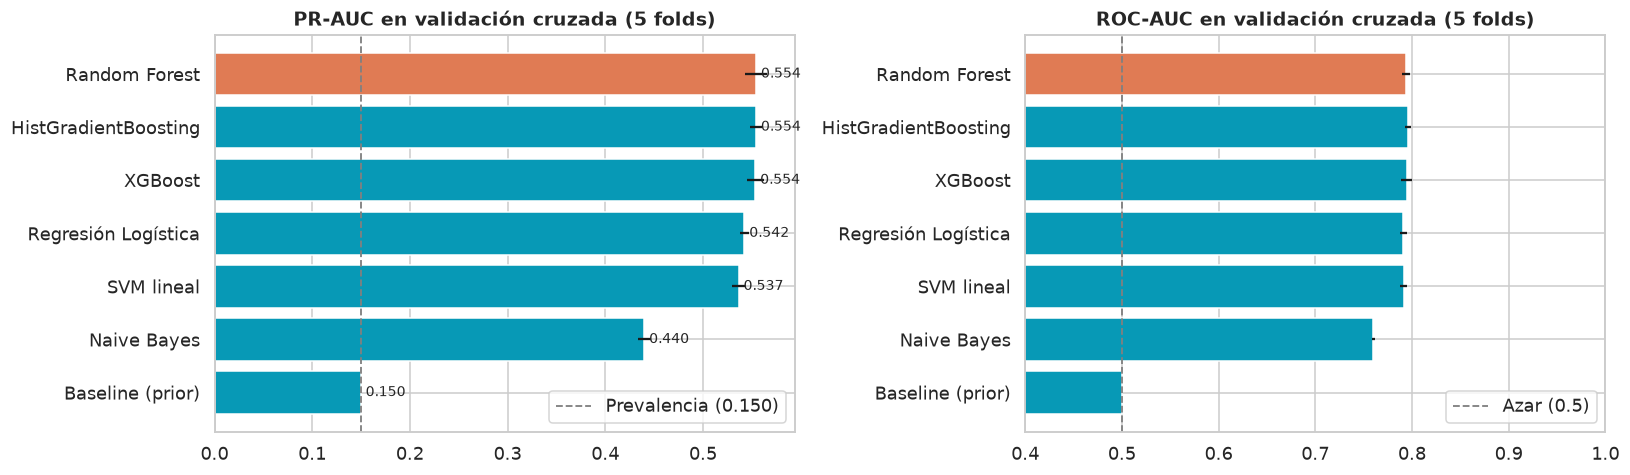

Mejor PR-AUC: Random Forest (0.5543 ± 0.0113)
Estadísticamente empatados (dentro de 1 std): Random Forest, HistGradientBoosting, XGBoost
Modelo seleccionado (el más simple entre los empatados): HistGradientBoosting


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
orden = cv_df.sort_values('pr_auc_mean')
colores = [PALETTE['terracota'] if m == orden.modelo.iat[-1] else PALETTE['bondi'] for m in orden.modelo]

axes[0].barh(orden.modelo, orden.pr_auc_mean, xerr=orden.pr_auc_std, color=colores, edgecolor='white')
axes[0].axvline(y_train.mean(), color='grey', ls='--', lw=1.2, label=f'Prevalencia ({y_train.mean():.3f})')
axes[0].set_title('PR-AUC en validación cruzada (5 folds)', fontweight='bold')
axes[0].legend(loc='lower right')
for i, v in enumerate(orden.pr_auc_mean):
    axes[0].text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)

axes[1].barh(orden.modelo, orden.roc_auc_mean, xerr=orden.roc_auc_std, color=colores, edgecolor='white')
axes[1].axvline(0.5, color='grey', ls='--', lw=1.2, label='Azar (0.5)')
axes[1].set_xlim(0.4, 1)
axes[1].set_title('ROC-AUC en validación cruzada (5 folds)', fontweight='bold')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

# Parsimonia: entre los modelos a menos de una desviación estándar del mejor, se elige el más simple.
# Orden fijo (no el tiempo medido, que varía entre ejecuciones) para que la selección sea reproducible.
COMPLEJIDAD = ['Baseline (prior)', 'Naive Bayes', 'Regresión Logística', 'SVM lineal',
               'HistGradientBoosting', 'XGBoost', 'Random Forest']
mejor = cv_df.iloc[0]
empatados = cv_df[cv_df.pr_auc_mean >= mejor.pr_auc_mean - mejor.pr_auc_std]
GANADOR_BASE = min(empatados.modelo, key=COMPLEJIDAD.index)
print(f'Mejor PR-AUC: {mejor.modelo} ({mejor.pr_auc_mean:.4f} ± {mejor.pr_auc_std:.4f})')
print(f'Estadísticamente empatados (dentro de 1 std): {", ".join(empatados.modelo)}')
print(f'Modelo seleccionado (el más simple entre los empatados): {GANADOR_BASE}')

**Regla de selección.** Las diferencias de PR-AUC entre los mejores modelos suelen ser menores que la variación entre folds. Para no elegir por ruido, se consideran empatados los modelos a menos de una desviación estándar del mejor y, entre ellos, se elige el más simple según un orden fijo: lineales < HistGradientBoosting (nativo de scikit-learn, sin dependencias extra en la API) < XGBoost < Random Forest (el más pesado de entrenar y serializar).

## 6. Ajuste de hiperparámetros y tratamiento del desbalance

### 6.1 Búsqueda aleatoria sobre el modelo ganador
`RandomizedSearchCV` (15 combinaciones, 3 folds, optimizando PR-AUC).

In [12]:
ESPACIOS = {
    'XGBoost': {
        'n_estimators': [300, 500, 800], 'learning_rate': [0.02, 0.05, 0.1], 'max_depth': [3, 4, 5, 6, 8],
        'min_child_weight': [1, 5, 10], 'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0],
        'reg_lambda': [1, 5, 10],
    },
    'HistGradientBoosting': {
        'learning_rate': [0.02, 0.05, 0.1], 'max_iter': [300, 500, 800], 'max_leaf_nodes': [15, 31, 63],
        'min_samples_leaf': [20, 50, 100], 'l2_regularization': [0, 1, 5],
    },
    'Random Forest': {
        'n_estimators': [200, 300], 'max_depth': [12, 16, 20], 'min_samples_leaf': [3, 5, 10, 20],
        'max_features': ['sqrt', 0.3],
    },
    'Regresión Logística': {'C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
}

pipe_base = Pipeline([('prep', construir_preprocesador(NUM, CAT)), ('clf', clone(MODELOS[GANADOR_BASE]))])
if GANADOR_BASE in ESPACIOS:
    busqueda = RandomizedSearchCV(
        pipe_base, {f'clf__{k}': v for k, v in ESPACIOS[GANADOR_BASE].items()}, n_iter=15,
        scoring='average_precision', cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE, n_jobs=1, refit=False)
    busqueda.fit(X_train, y_train)
    mejores = {k.removeprefix('clf__'): v for k, v in busqueda.best_params_.items()}
    pr_auc_default = cv_df.loc[cv_df.modelo == GANADOR_BASE, 'pr_auc_mean'].iat[0]
    print(f'PR-AUC configuración inicial (5 folds): {pr_auc_default:.4f}')
    print(f'PR-AUC mejor combinación   (3 folds): {busqueda.best_score_:.4f}')
    print('Mejores hiperparámetros:', mejores)
    clf_ajustado = clone(MODELOS[GANADOR_BASE]).set_params(**mejores)
    top_busqueda = (pd.DataFrame(busqueda.cv_results_)
                      .sort_values('rank_test_score')[['mean_test_score', 'std_test_score', 'params']].head(5))
else:
    mejores, clf_ajustado, top_busqueda = {}, clone(MODELOS[GANADOR_BASE]), None
    print(f'{GANADOR_BASE} no tiene espacio de búsqueda definido: se conserva su configuración.')
top_busqueda

PR-AUC configuración inicial (5 folds): 0.5543
PR-AUC mejor combinación   (3 folds): 0.5557
Mejores hiperparámetros: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 800, 'learning_rate': 0.05, 'l2_regularization': 5}


,mean_test_score,std_test_score,params
11,0.555724,0.006503,"{'clf__min_samples_leaf': 100, 'clf__max_leaf_..."
14,0.555601,0.005719,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n..."
3,0.555057,0.005507,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n..."
12,0.554536,0.003945,"{'clf__min_samples_leaf': 100, 'clf__max_leaf_..."
4,0.554331,0.005849,"{'clf__min_samples_leaf': 50, 'clf__max_leaf_n..."


### 6.2 Ponderación de clases vs SMOTE vs sin tratamiento
SMOTE se aplica **dentro** del pipeline (`imblearn`), así el sobremuestreo ocurre solo en los folds de entrenamiento y nunca contamina la validación.

In [13]:
def sin_ponderacion(estimador):
    est = clone(estimador)
    params = est.get_params()
    if 'scale_pos_weight' in params:
        est.set_params(scale_pos_weight=1)
    if 'class_weight' in params:
        est.set_params(class_weight=None)
    return est


ESTRATEGIAS = {
    'Sin tratamiento': Pipeline([('prep', construir_preprocesador(NUM, CAT)), ('clf', sin_ponderacion(clf_ajustado))]),
    'Ponderación de clases': Pipeline([('prep', construir_preprocesador(NUM, CAT)), ('clf', clone(clf_ajustado))]),
    'SMOTE': ImbPipeline([('prep', construir_preprocesador(NUM, CAT)),
                          ('smote', SMOTE(random_state=RANDOM_STATE)),
                          ('clf', sin_ponderacion(clf_ajustado))]),
}
cv3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
filas = []
for nombre, pipe in ESTRATEGIAS.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv3, scoring=SCORING)
    filas.append({'estrategia': nombre, **{m: res[f'test_{m}'].mean() for m in SCORING}})
desbalance_df = pd.DataFrame(filas).sort_values('pr_auc', ascending=False).reset_index(drop=True)

ESTRATEGIA = desbalance_df.estrategia.iat[0]
print(f'Estrategia elegida (mayor PR-AUC): {ESTRATEGIA}')
desbalance_df.round(4)

Estrategia elegida (mayor PR-AUC): Sin tratamiento


,estrategia,pr_auc,roc_auc,f1,precision,recall,balanced_accuracy
0,Sin tratamiento,0.5558,0.7928,0.5277,0.7714,0.4010,0.6901
1,Ponderación de clases,0.5557,0.7933,0.5198,0.4585,0.6001,0.7376
2,SMOTE,0.5469,0.7886,0.5364,0.7505,0.4174,0.6965


PR-AUC y ROC-AUC no dependen del umbral, así que el tratamiento del desbalance cambia sobre todo **dónde** cae el umbral 0.5 (recall vs precision), no la capacidad de ordenar pedidos por riesgo. Como el umbral se calibra aparte, se elige la estrategia con mejor PR-AUC.

## 7. Selección del umbral de decisión

El umbral se elige con predicciones **out-of-fold** del entrenamiento (nunca con el test) para maximizar F1 de la clase negativa.

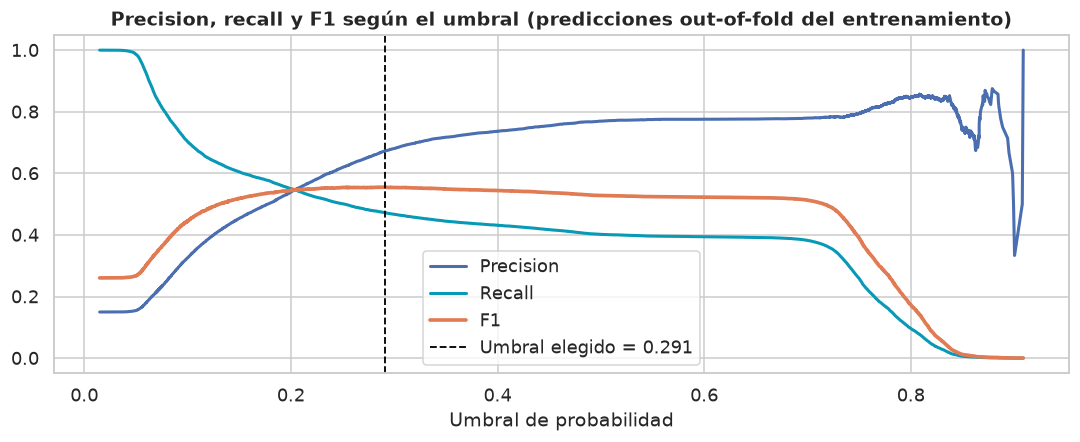

Modelo final: HistGradientBoosting (sin tratamiento, ajustado)
Umbral que maximiza F1 (OOF): 0.2907 | F1 OOF = 0.5554 | PR-AUC OOF = 0.5552


In [14]:
pipe_final = clone(ESTRATEGIAS[ESTRATEGIA])
GANADOR = f'{GANADOR_BASE} ({ESTRATEGIA.lower()}{", ajustado" if mejores else ""})'

oof = cross_val_predict(pipe_final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
UMBRAL = float(thr[np.argmax(f1s)])

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(thr, prec[:-1], color=PALETTE['san_marino'], lw=2, label='Precision')
ax.plot(thr, rec[:-1], color=PALETTE['bondi'], lw=2, label='Recall')
ax.plot(thr, f1s, color=PALETTE['terracota'], lw=2.4, label='F1')
ax.axvline(UMBRAL, color='black', ls='--', lw=1.2, label=f'Umbral elegido = {UMBRAL:.3f}')
ax.set_xlabel('Umbral de probabilidad')
ax.set_title('Precision, recall y F1 según el umbral (predicciones out-of-fold del entrenamiento)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Modelo final: {GANADOR}')
print(f'Umbral que maximiza F1 (OOF): {UMBRAL:.4f} | F1 OOF = {f1s.max():.4f} | PR-AUC OOF = {average_precision_score(y_train, oof):.4f}')

## 8. Evaluación final en el conjunto de prueba (jun–ago 2018)

El modelo se reentrena con todo el entrenamiento y se evalúa **una sola vez** sobre el test. Como referencia también se reentrenan los modelos base para comparar curvas en datos no vistos.

In [15]:
pipe_final.fit(X_train, y_train)
p_test = pipe_final.predict_proba(X_test)[:, 1]
y_pred = (p_test >= UMBRAL).astype(int)


def metricas(y, p, pred):
    return {
        'roc_auc': roc_auc_score(y, p),
        'pr_auc': average_precision_score(y, p),
        'f1': f1_score(y, pred),
        'precision': precision_score(y, pred),
        'recall': recall_score(y, pred),
        'balanced_accuracy': balanced_accuracy_score(y, pred),
        'brier': brier_score_loss(y, p),
    }


METRICAS_TEST = metricas(y_test, p_test, y_pred)
print(f'Modelo: {GANADOR} | umbral = {UMBRAL:.3f} | prevalencia test = {y_test.mean():.4f}\n')
print(classification_report(y_test, y_pred, target_names=['Positiva/neutra (0)', 'Negativa (1)'], digits=4))
pd.Series(METRICAS_TEST).round(4).to_frame('test')

Modelo: HistGradientBoosting (sin tratamiento, ajustado) | umbral = 0.291 | prevalencia test = 0.1067

                     precision    recall  f1-score   support

Positiva/neutra (0)     0.9226    0.9740    0.9476     16784
       Negativa (1)     0.5925    0.3162    0.4124      2005

           accuracy                         0.9038     18789
          macro avg     0.7576    0.6451    0.6800     18789
       weighted avg     0.8874    0.9038    0.8905     18789



,test
roc_auc,0.7241
pr_auc,0.3999
f1,0.4124
precision,0.5925
recall,0.3162
balanced_accuracy,0.6451
brier,0.0783


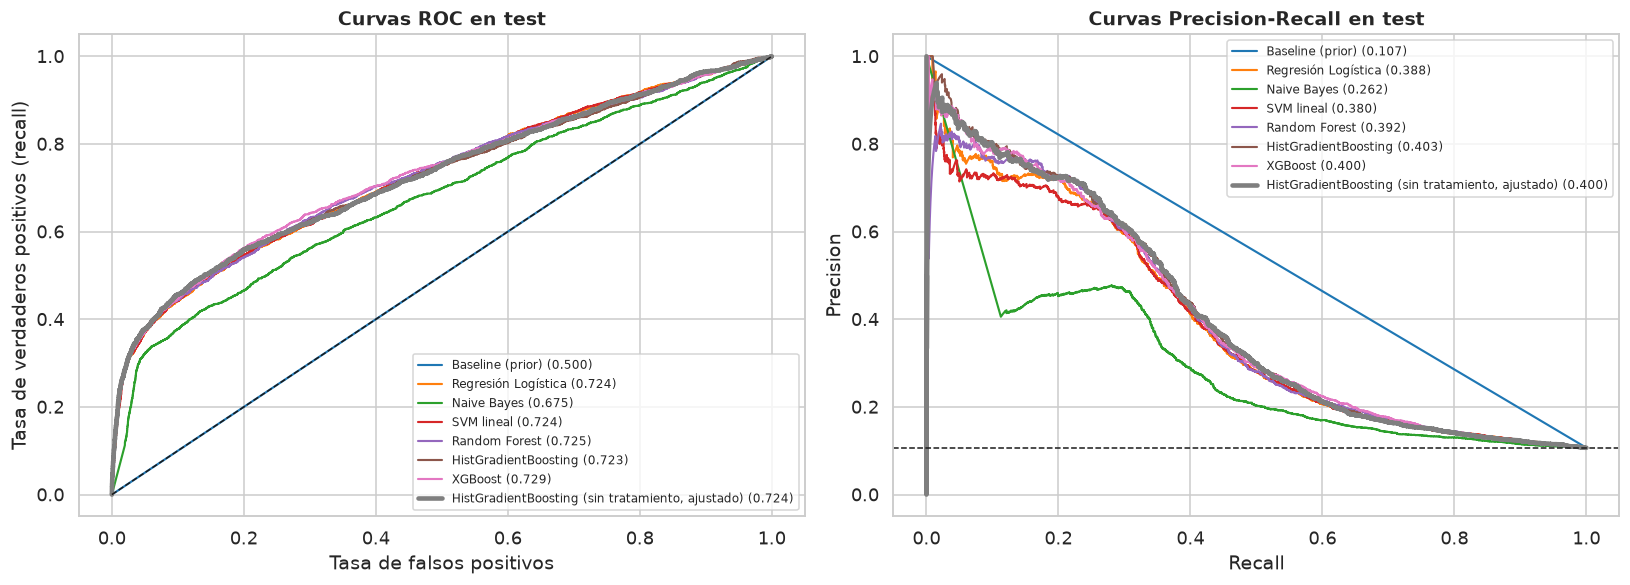

,modelo,roc_auc,pr_auc
0,HistGradientBoosting,0.7227,0.4029
1,"HistGradientBoosting (sin tratamiento, ajustado)",0.7241,0.3999
2,XGBoost,0.7286,0.3998
3,Random Forest,0.7251,0.3920
4,Regresión Logística,0.7237,0.3881
5,SVM lineal,0.7239,0.3803
6,Naive Bayes,0.6752,0.2624
7,Baseline (prior),0.5000,0.1067


In [16]:
probas_test = {}
filas_test = []
for nombre, modelo in MODELOS.items():
    pipe = Pipeline([('prep', construir_preprocesador(NUM, CAT)), ('clf', clone(modelo))]).fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    probas_test[nombre] = p
    filas_test.append({'modelo': nombre, 'roc_auc': roc_auc_score(y_test, p), 'pr_auc': average_precision_score(y_test, p)})
probas_test[GANADOR] = p_test
filas_test.append({'modelo': GANADOR, 'roc_auc': METRICAS_TEST['roc_auc'], 'pr_auc': METRICAS_TEST['pr_auc']})
test_df = pd.DataFrame(filas_test).sort_values('pr_auc', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
paleta = sns.color_palette('tab10', len(probas_test))
for (nombre, p), color in zip(probas_test.items(), paleta):
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    ancho = 3 if nombre == GANADOR else 1.4
    axes[0].plot(fpr, tpr, lw=ancho, color=color, label=f'{nombre} ({roc_auc_score(y_test, p):.3f})')
    axes[1].plot(rc, pr, lw=ancho, color=color, label=f'{nombre} ({average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos (recall)')
axes[0].set_title('Curvas ROC en test', fontweight='bold')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1)
axes[1].set(xlabel='Recall', ylabel='Precision')
axes[1].set_title('Curvas Precision-Recall en test', fontweight='bold')
for ax in axes:
    ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()
test_df.round(4)

### 8.1 Matriz de confusión y calibración

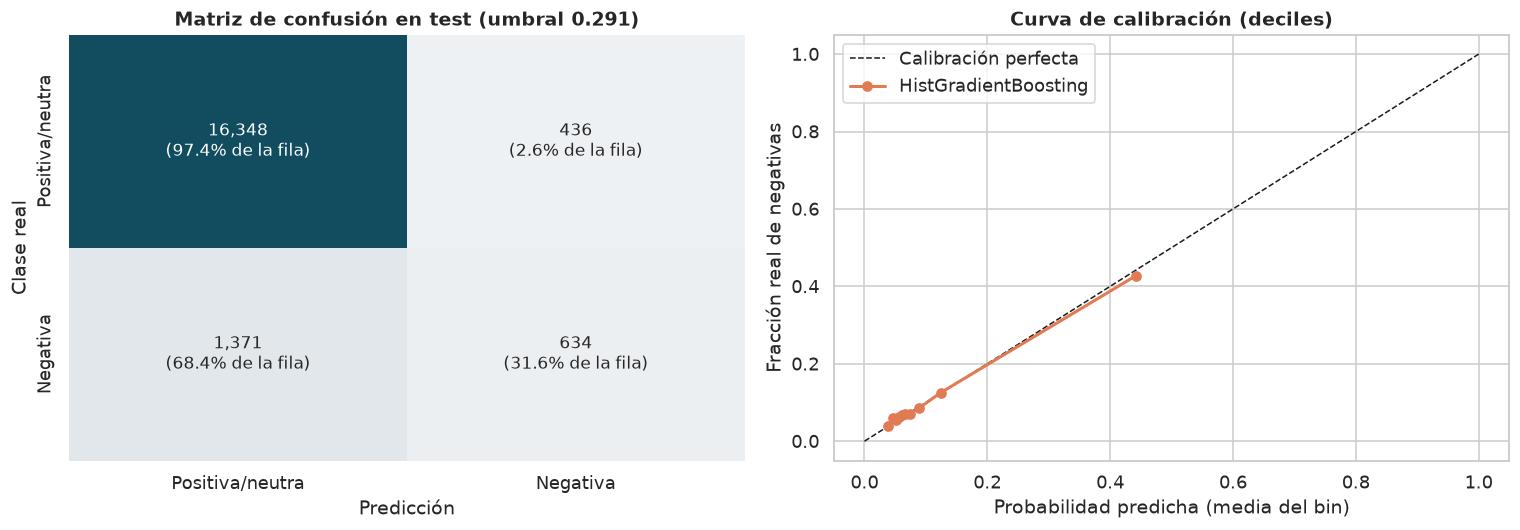

VP=634  FP=436  FN=1,371  VN=16,348


In [17]:
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

etiquetas = ['Positiva/neutra', 'Negativa']
anotaciones = np.array([[f'{v:,}\n({v / cm[i].sum() * 100:.1f}% de la fila)' for v in fila] for i, fila in enumerate(cm)])
sns.heatmap(cm, annot=anotaciones, fmt='', cmap=sns.light_palette(PALETTE['eden'], as_cmap=True), cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[0], annot_kws={'fontsize': 11})
axes[0].set(xlabel='Predicción', ylabel='Clase real')
axes[0].set_title(f'Matriz de confusión en test (umbral {UMBRAL:.3f})', fontweight='bold')

frac_pos, prob_media = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Calibración perfecta')
axes[1].plot(prob_media, frac_pos, 'o-', color=PALETTE['terracota'], lw=2, label=GANADOR_BASE)
axes[1].set(xlabel='Probabilidad predicha (media del bin)', ylabel='Fracción real de negativas')
axes[1].set_title('Curva de calibración (deciles)', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'VP={tp:,}  FP={fp:,}  FN={fn:,}  VN={tn:,}')

> La ponderación de clases y SMOTE **inflan** las probabilidades respecto a la frecuencia real. Como la estrategia elegida fue *sin tratamiento*, la curva queda cerca de la diagonal: la probabilidad puede leerse como frecuencia esperada (por ejemplo, para estimar cuántas reseñas negativas habrá en un lote). Si la prevalencia cambia mucho en producción, conviene recalibrar con `CalibratedClassifierCV`.

### 8.2 Curva de ganancia: ¿cuánto se gana priorizando por riesgo?
Uso operativo: el equipo de postventa no puede contactar a todos. Se ordenan los pedidos del test por probabilidad y se mide qué porcentaje de las negativas reales cae en cada decil.

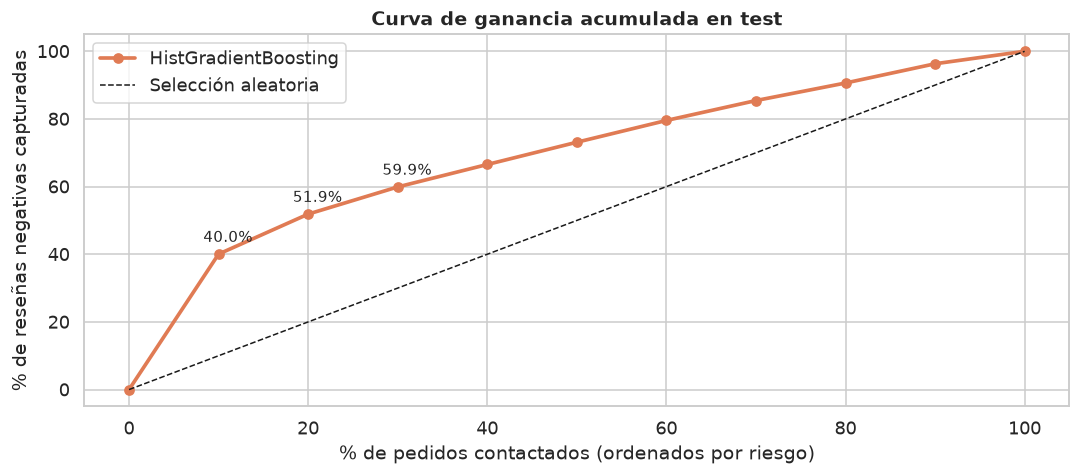

,pedidos,negativas,tasa_negativas,prob_min,captura_acumulada_%,lift
decil,,,,,,
1,1878,803,0.428,0.168,40.050,4.007
2,1879,237,0.126,0.100,51.870,1.182
3,1879,161,0.086,0.080,59.900,0.803
4,1879,133,0.071,0.070,66.534,0.663
5,1879,132,0.070,0.063,73.117,0.658
6,1879,129,0.069,0.058,79.551,0.643
7,1879,118,0.063,0.054,85.436,0.588
8,1879,104,0.055,0.049,90.623,0.519
9,1879,114,0.061,0.043,96.309,0.569


In [18]:
orden_riesgo = pd.DataFrame({'y': y_test.to_numpy(), 'p': p_test}).sort_values('p', ascending=False).reset_index(drop=True)
orden_riesgo['decil'] = np.ceil((orden_riesgo.index + 1) / len(orden_riesgo) * 10).astype(int)
ganancia = orden_riesgo.groupby('decil').agg(pedidos=('y', 'size'), negativas=('y', 'sum'), tasa_negativas=('y', 'mean'),
                                             prob_min=('p', 'min'))
ganancia['captura_acumulada_%'] = ganancia.negativas.cumsum() / ganancia.negativas.sum() * 100
ganancia['lift'] = ganancia.tasa_negativas / orden_riesgo.y.mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.r_[0, ganancia.index * 10]
ax.plot(x, np.r_[0, ganancia['captura_acumulada_%']], 'o-', color=PALETTE['terracota'], lw=2.4, label=GANADOR_BASE)
ax.plot([0, 100], [0, 100], 'k--', lw=1, label='Selección aleatoria')
for d in (1, 2, 3):
    v = ganancia.loc[d, 'captura_acumulada_%']
    ax.annotate(f'{v:.1f}%', (d * 10, v), textcoords='offset points', xytext=(-10, 8), fontsize=10)
ax.set(xlabel='% de pedidos contactados (ordenados por riesgo)', ylabel='% de reseñas negativas capturadas')
ax.set_title('Curva de ganancia acumulada en test', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()
ganancia.round(3)

## 9. Interpretabilidad del modelo

### 9.1 Importancia por permutación (sobre variables originales, en test)
Mide cuánto cae la PR-AUC al desordenar cada variable. Es agnóstica al modelo y se calcula sobre datos no vistos.

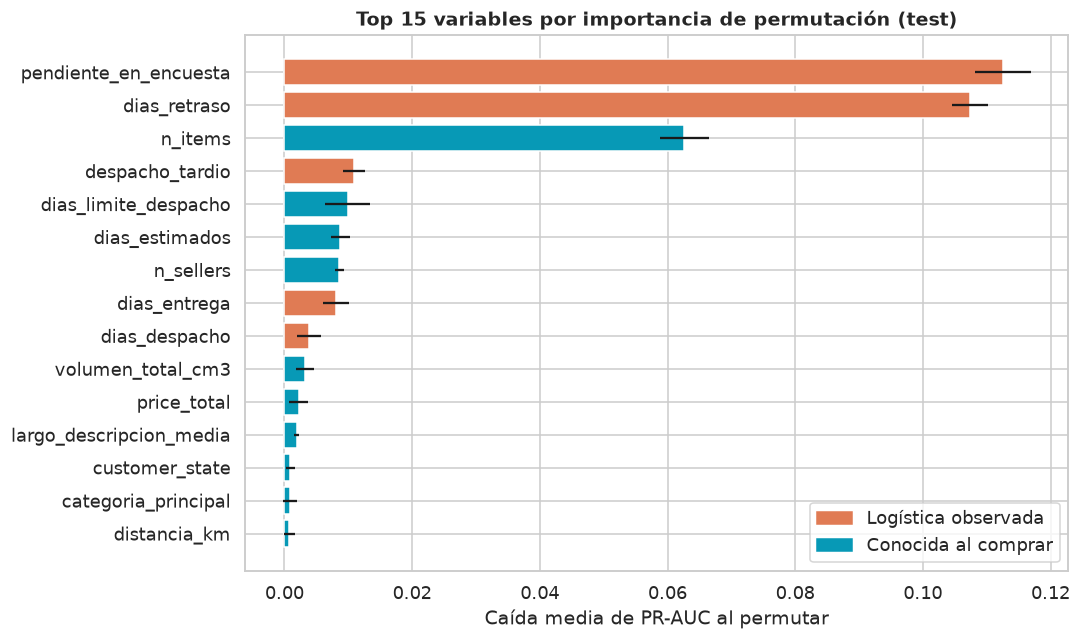

,variable,importancia,std,familia
0,pendiente_en_encuesta,0.1125,0.0044,Logística observada
1,dias_retraso,0.1074,0.0028,Logística observada
2,n_items,0.0626,0.0039,Conocida al comprar
3,despacho_tardio,0.0109,0.0018,Logística observada
4,dias_limite_despacho,0.0099,0.0036,Conocida al comprar
5,dias_estimados,0.0087,0.0015,Conocida al comprar
6,n_sellers,0.0086,0.0007,Conocida al comprar
7,dias_entrega,0.0081,0.0020,Logística observada
8,dias_despacho,0.0039,0.0019,Logística observada
9,volumen_total_cm3,0.0032,0.0014,Conocida al comprar


In [19]:
muestra_imp = X_test.sample(n=min(8000, len(X_test)), random_state=RANDOM_STATE)
imp = permutation_importance(pipe_final, muestra_imp, y_test.loc[muestra_imp.index], scoring='average_precision',
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importancias = (pd.DataFrame({'variable': FEATURES, 'importancia': imp.importances_mean, 'std': imp.importances_std})
                  .sort_values('importancia', ascending=False).reset_index(drop=True))
importancias['familia'] = np.where(importancias.variable.isin(NUM_ENCUESTA), 'Logística observada', 'Conocida al comprar')

top = importancias.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.variable, top.importancia, xerr=top['std'], edgecolor='white',
        color=[PALETTE['terracota'] if f.startswith('Log') else PALETTE['bondi'] for f in top.familia])
ax.set_xlabel('Caída media de PR-AUC al permutar')
ax.set_title('Top 15 variables por importancia de permutación (test)', fontweight='bold')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE['terracota']), plt.Rectangle((0, 0), 1, 1, color=PALETTE['bondi'])],
          labels=['Logística observada', 'Conocida al comprar'], loc='lower right')
plt.tight_layout()
plt.show()
importancias.head(15).round(4)

### 9.2 SHAP: dirección del efecto
La importancia por permutación dice *cuánto* importa una variable; SHAP muestra *en qué dirección* empuja el riesgo (rojo = valor alto de la variable).

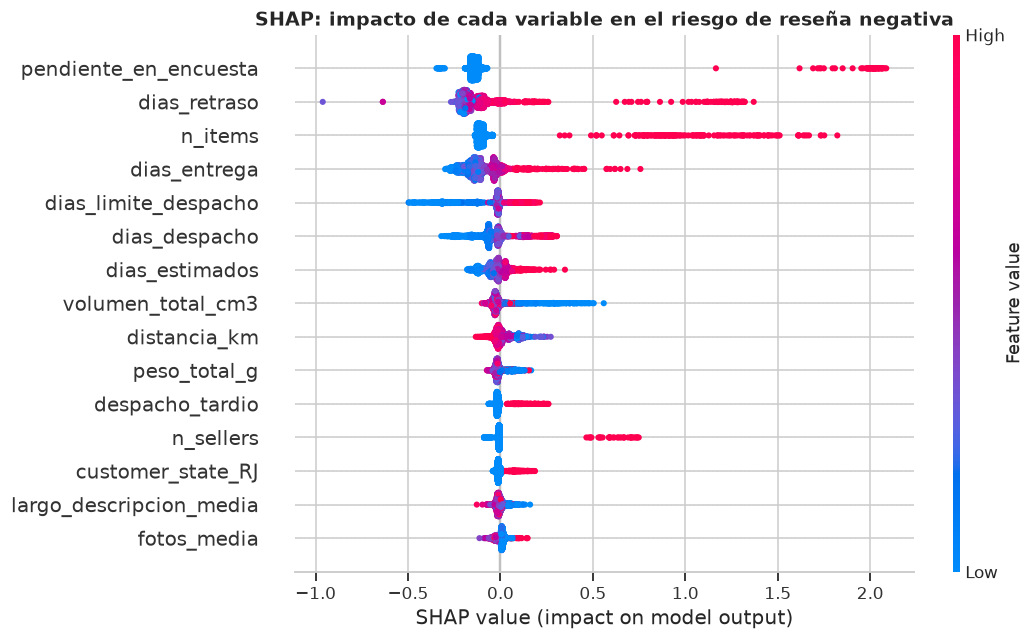

In [20]:
prep_fit, clf_fit = pipe_final.named_steps['prep'], pipe_final.named_steps['clf']
# TreeExplainer es exacto pero costoso en bosques profundos: muestra menor para Random Forest
n_shap = 500 if isinstance(clf_fit, RandomForestClassifier) else 2000
muestra_shap = X_test.sample(n=min(n_shap, len(X_test)), random_state=RANDOM_STATE)
X_shap = pd.DataFrame(prep_fit.transform(muestra_shap), columns=prep_fit.get_feature_names_out())

valores_shap = shap.TreeExplainer(clf_fit)(X_shap).values
if valores_shap.ndim == 3:
    valores_shap = valores_shap[:, :, 1]
shap.summary_plot(valores_shap, X_shap, max_display=15, show=False, plot_size=(10, 6))
plt.title('SHAP: impacto de cada variable en el riesgo de reseña negativa', fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Escenario complementario: predicción al momento de la compra

Mismo algoritmo, configuración y pedidos (mismo train y mismo test), pero **solo con variables conocidas en el checkout**. Responde: *¿cuánto del riesgo se puede anticipar antes de despachar y cuánto aporta el seguimiento logístico?*

In [21]:
FEATURES_COMPRA = NUM_COMPRA + CAT
pasos = [('prep', construir_preprocesador(NUM_COMPRA, CAT))]
if ESTRATEGIA == 'SMOTE':
    pasos.append(('smote', SMOTE(random_state=RANDOM_STATE)))
pipe_compra = ImbPipeline(pasos + [('clf', clone(pipe_final.named_steps['clf']))]).fit(X_train[FEATURES_COMPRA], y_train)
pc_test = pipe_compra.predict_proba(X_test[FEATURES_COMPRA])[:, 1]


def captura_top(y, p, frac=0.10):
    orden = np.argsort(-p)
    return np.asarray(y)[orden[: int(len(orden) * frac)]].sum() / np.sum(y) * 100


escenarios_df = pd.DataFrame([
    {'escenario': 'Al enviar la encuesta (modelo principal)', 'variables': len(FEATURES),
     'roc_auc': METRICAS_TEST['roc_auc'], 'pr_auc': METRICAS_TEST['pr_auc'],
     'lift_pr_auc': METRICAS_TEST['pr_auc'] / y_test.mean(), 'captura_top10_%': captura_top(y_test, p_test)},
    {'escenario': 'Al comprar (sin logística)', 'variables': len(FEATURES_COMPRA),
     'roc_auc': roc_auc_score(y_test, pc_test), 'pr_auc': average_precision_score(y_test, pc_test),
     'lift_pr_auc': average_precision_score(y_test, pc_test) / y_test.mean(), 'captura_top10_%': captura_top(y_test, pc_test)},
])
escenarios_df.round(4)

,escenario,variables,roc_auc,pr_auc,lift_pr_auc,captura_top10_%
0,Al enviar la encuesta (modelo principal),33,0.7241,0.3999,3.7472,40.0499
1,Al comprar (sin logística),26,0.6018,0.1809,1.6951,20.6484


`lift_pr_auc` = PR-AUC / prevalencia: cuántas veces mejor que el azar ordena el modelo.

## 11. Generación y validación de artefactos de contrato

Se exportan los cuatro archivos que consume el dashboard:
1. `model.joblib`: pipeline completo (preprocesamiento + modelo), umbral y lista de variables.
2. `results.csv`: muestra estratificada de 500 pedidos del test con clase real, probabilidad y predicción.
3. `chart_data.json`: comparación de modelos, matriz de confusión, curvas ROC/PR, calibración, ganancia, importancias y escenarios.
4. `manifest.json`: manifiesto validado contra `docs/module_contract.schema.json`.

In [22]:
r4 = lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else round(float(v), 4)


def submuestrear(*arrays, n=120):
    idx = np.unique(np.linspace(0, len(arrays[0]) - 1, n).astype(int))
    return [[r4(v) for v in np.asarray(a)[idx]] for a in arrays]


# 11.1 model.joblib
joblib.dump({
    'pipeline': pipe_final,
    'threshold': UMBRAL,
    'features_num': NUM,
    'features_cat': CAT,
    'target': 'review_negativa (review_score <= 2)',
    'momento_prediccion': 'Al enviar la encuesta de satisfacción (review_creation_date), antes de la respuesta del cliente',
    'winner_name': GANADOR,
}, ARTIFACTS_DIR / 'model.joblib', compress=3)
print('✓ Guardado: model.joblib')

# 11.2 results.csv (500 pedidos del test, estratificado por clase real)
resultados = pd.DataFrame({
    'order_id': test.order_id.to_numpy(),
    'fecha_compra': test.order_purchase_timestamp.dt.date.to_numpy(),
    'categoria_principal': test.categoria_principal.to_numpy(),
    'dias_retraso': test.dias_retraso.round(1).to_numpy(),
    'clase_real': y_test.to_numpy(),
    'probabilidad': p_test.round(4),
    'prediccion': y_pred,
})
n_neg = int(round(500 * y_test.mean()))
muestra = pd.concat([
    resultados[resultados.clase_real == 1].sample(n=n_neg, random_state=RANDOM_STATE),
    resultados[resultados.clase_real == 0].sample(n=500 - n_neg, random_state=RANDOM_STATE),
]).sort_values('probabilidad', ascending=False).reset_index(drop=True)
muestra.to_csv(ARTIFACTS_DIR / 'results.csv', index=False)
print(f'✓ Guardado: results.csv ({len(muestra)} filas)')

# 11.3 chart_data.json
fpr, tpr, _ = roc_curve(y_test, p_test)
pr, rc, _ = precision_recall_curve(y_test, p_test)
fpr_s, tpr_s = submuestrear(fpr, tpr)
rc_s, pr_s = submuestrear(rc[::-1], pr[::-1])
chart_data = {
    'threshold': r4(UMBRAL),
    'prevalence_test': r4(y_test.mean()),
    'model_comparison_cv': [{k: (r4(v) if not isinstance(v, str) else v) for k, v in fila.items()}
                            for fila in cv_df.drop(columns='segundos').to_dict(orient='records')],
    'model_comparison_test': [{k: (r4(v) if not isinstance(v, str) else v) for k, v in fila.items()}
                              for fila in test_df.to_dict(orient='records')],
    'imbalance_strategies': [{k: (r4(v) if not isinstance(v, str) else v) for k, v in fila.items()}
                             for fila in desbalance_df.to_dict(orient='records')],
    'confusion_matrix': {'labels': ['Positiva/neutra (0)', 'Negativa (1)'], 'matrix': cm.tolist(),
                         'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
    'roc_curve': {'fpr': fpr_s, 'tpr': tpr_s, 'auc': r4(METRICAS_TEST['roc_auc'])},
    'pr_curve': {'recall': rc_s, 'precision': pr_s, 'average_precision': r4(METRICAS_TEST['pr_auc'])},
    'calibration': {'prob_media': [r4(v) for v in prob_media], 'fraccion_positivos': [r4(v) for v in frac_pos]},
    'gains_by_decile': [{'decil': int(d), **{k: r4(v) for k, v in fila.items()}}
                        for d, fila in ganancia.to_dict(orient='index').items()],
    'feature_importance': [{'variable': f.variable, 'familia': f.familia, 'importancia': r4(f.importancia), 'std': r4(f.std)}
                           for f in importancias.head(15).itertuples()],
    'scenario_comparison': [{k: (r4(v) if not isinstance(v, str) else v) for k, v in fila.items()}
                            for fila in escenarios_df.to_dict(orient='records')],
}
with open(ARTIFACTS_DIR / 'chart_data.json', 'w', encoding='utf-8') as f:
    json.dump(chart_data, f, ensure_ascii=False, indent=2)
print('✓ Guardado: chart_data.json')

✓ Guardado: model.joblib
✓ Guardado: results.csv (500 filas)
✓ Guardado: chart_data.json


In [23]:
# 11.4 manifest.json
top3 = importancias.variable.head(3).tolist()
dec1, dec3 = ganancia.loc[1], ganancia.loc[3]
esc_compra = escenarios_df.iloc[1]
pr_cv_ganador = cv_df.loc[cv_df.modelo == GANADOR_BASE, 'pr_auc_mean'].iat[0]
tasas = estado.tasa_negativas * 100

conclusiones = [
    f'Priorización accionable: contactar el 10% de pedidos con mayor riesgo captura el {dec1["captura_acumulada_%"]:.1f}% de las reseñas negativas '
    f'(lift {dec1["lift"]:.1f}x); con el 30% se captura el {dec3["captura_acumulada_%"]:.1f}%.',
    f'La promesa de entrega es la palanca principal: los pedidos pendientes al enviar la encuesta tienen {tasas["Pendiente"]:.1f}% de negativas y los '
    f'entregados tarde {tasas["Entregado tarde"]:.1f}%, frente a {tasas["Entregado a tiempo"]:.1f}% de los puntuales. Variables más influyentes: {", ".join(top3)}.',
    f'Con el umbral {UMBRAL:.2f} el modelo detecta el {METRICAS_TEST["recall"] * 100:.1f}% de las negativas con una precisión del {METRICAS_TEST["precision"] * 100:.1f}% '
    f'(PR-AUC {METRICAS_TEST["pr_auc"]:.3f} frente a una prevalencia de {y_test.mean():.3f}).',
    f'Al momento de la compra el riesgo es poco anticipable (PR-AUC {esc_compra.pr_auc:.3f} vs {METRICAS_TEST["pr_auc"]:.3f} con seguimiento logístico): '
    'la acción preventiva debe apoyarse en el monitoreo del despacho y la entrega, no solo en el perfil del pedido.',
]
limitaciones = [
    'Momento de predicción: el modelo se aplica al enviar la encuesta; para usarlo antes (al comprar o al despachar) el desempeño cae, como muestra el escenario complementario.',
    f'Deriva temporal: la tasa de negativas varía entre meses (picos en nov-2017 y feb–mar 2018); el modelo debe reentrenarse periódicamente y vigilar la prevalencia (test: {y_test.mean() * 100:.1f}%).',
    ('Probabilidades no calibradas: la ponderación de clases o SMOTE inflan las probabilidades; sirven para ordenar el riesgo, no como frecuencia esperada.'
     if ESTRATEGIA != 'Sin tratamiento' else
     f'Brecha validación–test: la PR-AUC baja de {pr_cv_ganador:.3f} (CV) a {METRICAS_TEST["pr_auc"]:.3f} (test) sobre todo porque la prevalencia cae '
     f'de {y_train.mean() * 100:.1f}% a {y_test.mean() * 100:.1f}%; el lift sobre el azar se mantiene, pero la ROC-AUC también desciende, señal de deriva a monitorear.'),
    'Sin variables de texto ni historial del vendedor: el comentario de la reseña es posterior a la predicción y el historial de reputación del vendedor no se incluyó para evitar fuga temporal.',
]

manifest = {
    'status': 'Completado',
    'model_name': 'Riesgo de reseña negativa',
    'version': '1.0.0',
    'generated_at': datetime.now(timezone.utc).isoformat(),
    'dataset': 'Olist Brazilian E-Commerce',
    'period': f'Entrenamiento {train.order_purchase_timestamp.min():%Y-%m} a {train.order_purchase_timestamp.max():%Y-%m}; '
              f'prueba {test.order_purchase_timestamp.min():%Y-%m} a {test.order_purchase_timestamp.max():%Y-%m}',
    'metrics': {
        'roc_auc': r4(METRICAS_TEST['roc_auc']),
        'pr_auc': r4(METRICAS_TEST['pr_auc']),
        'f1': r4(METRICAS_TEST['f1']),
        'precision': r4(METRICAS_TEST['precision']),
        'recall': r4(METRICAS_TEST['recall']),
        'balanced_accuracy': r4(METRICAS_TEST['balanced_accuracy']),
        'brier': r4(METRICAS_TEST['brier']),
        'umbral': r4(UMBRAL),
        'prevalencia_test': r4(y_test.mean()),
        'cv_pr_auc': r4(pr_cv_ganador),
        'n_train': int(len(train)),
        'n_test': int(len(test)),
    },
    'winner': GANADOR,
    'results_path': 'artifacts/classification/results.csv',
    'chart_data_path': 'artifacts/classification/chart_data.json',
    'business_conclusions': conclusiones,
    'limitations': limitaciones,
    'serialized_model_path': 'artifacts/classification/model.joblib',
}
with open(ARTIFACTS_DIR / 'manifest.json', 'w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

schema = json.loads((ROOT / 'docs' / 'module_contract.schema.json').read_text(encoding='utf-8'))
jsonschema.validate(manifest, schema)
print('✓ Guardado: manifest.json — cumple docs/module_contract.schema.json')

# Verificación: el modelo serializado reproduce las predicciones
cargado = joblib.load(ARTIFACTS_DIR / 'model.joblib')
assert np.allclose(cargado['pipeline'].predict_proba(X_test)[:, 1], p_test)
print('✓ model.joblib recargado reproduce las probabilidades del test')
print(f'\nTiempo total del notebook: {(time.time() - t_inicio) / 60:.1f} min')
print(json.dumps(manifest['metrics'], indent=2))

✓ Guardado: manifest.json — cumple docs/module_contract.schema.json
✓ model.joblib recargado reproduce las probabilidades del test

Tiempo total del notebook: 7.2 min
{
  "roc_auc": 0.7241,
  "pr_auc": 0.3999,
  "f1": 0.4124,
  "precision": 0.5925,
  "recall": 0.3162,
  "balanced_accuracy": 0.6451,
  "brier": 0.0783,
  "umbral": 0.2907,
  "prevalencia_test": 0.1067,
  "cv_pr_auc": 0.5543,
  "n_train": 78801,
  "n_test": 18789
}


## 12. Conclusiones

### Desempeño del modelo
1. **Modelo seleccionado: HistGradientBoosting** (sin reponderación, hiperparámetros ajustados). Random Forest, HistGradientBoosting y XGBoost quedaron estadísticamente empatados en validación cruzada (PR-AUC ≈ 0.554, diferencias menores a una desviación estándar); se eligió HistGradientBoosting por ser el más eficiente de los tres (≈3× más rápido que Random Forest y con un modelo serializado de ~150 KB).
2. **Test (jun–ago 2018, nunca visto):** PR-AUC **0.400** frente a una prevalencia de 0.107 (**3.7× mejor que el azar**), ROC-AUC 0.724. El lift sobre el azar es el mismo que en validación cruzada (0.554 / 0.150 ≈ 3.7×): la caída en la PR-AUC absoluta se explica principalmente porque el test tiene menos negativas. La ROC-AUC sí baja (0.79 → 0.72), lo que indica deriva temporal real.
3. **Modelos lineales competitivos:** la Regresión Logística (PR-AUC CV 0.542) queda muy cerca de los ensambles. Es una alternativa válida si se prioriza la interpretabilidad. Naive Bayes es claramente inferior (0.440) por su supuesto de independencia entre variables muy correlacionadas (días de entrega, retraso, despacho).
4. **Desbalance:** ni la ponderación de clases ni SMOTE mejoraron la PR-AUC (0.556 / 0.556 / 0.547). Solo desplazan el punto de operación, algo que el ajuste del umbral hace de forma más transparente. SMOTE fue algo peor porque interpola sobre variables One-Hot y genera pedidos sintéticos poco realistas. Al no reponderar, las probabilidades quedan bien calibradas.

### Hallazgos de negocio
1. **Priorización:** contactar al **10%** de pedidos con mayor riesgo captura el **40.0%** de las reseñas negativas (lift 4.0×); con el 30% se captura el 59.9%. Con el umbral 0.291, de cada 10 alertas ~6 terminan en reseña negativa (precisión 59.3%, recall 31.6%).
2. **El incumplimiento de la promesa de entrega domina el riesgo:** los pedidos **pendientes** al enviar la encuesta tienen **74.0%** de negativas; los entregados tarde, 19.5%; los puntuales, 9.2%. `pendiente_en_encuesta` y `dias_retraso` son, por amplio margen, las variables más importantes.
3. **Pedidos con varios ítems o varios vendedores:** `n_items` es la tercera variable y la principal entre las conocidas al comprar. SHAP muestra que más ítems y más de un vendedor elevan el riesgo, consistente con entregas parciales o separadas que el cliente percibe como incompletas.
4. **Poco anticipable al comprar:** con solo las variables del checkout, la PR-AUC cae a 0.181 (1.7× el azar) y el top 10% captura el 20.6%. La mayor parte del riesgo se genera en la ejecución logística, no en el perfil del pedido.

### Recomendaciones
- **Alerta proactiva:** marcar los pedidos que llegan a la fecha prometida sin entregarse y contactarlos *antes* de la encuesta (nueva fecha, compensación, seguimiento).
- **Pedidos multivendedor:** comunicar explícitamente los envíos separados y monitorear su cumplimiento.
- **Revisar la promesa:** las fechas estimadas holgadas reducen el riesgo (SHAP de `dias_estimados` y `dias_limite_despacho`). Conviene coordinar con el módulo de regresión, que estima la fecha de entrega.

### Limitaciones
- El modelo se aplica al enviar la encuesta; antes de ese momento (al comprar o al despachar) su capacidad es menor.
- Deriva temporal: la tasa de negativas varía entre 10% y 23% según el mes. Hay que reentrenar periódicamente y vigilar la prevalencia y la ROC-AUC.
- No se usan el texto de la reseña (es posterior a la predicción; corresponde al módulo NLP) ni el historial de reputación del vendedor, que requeriría una ventana temporal estricta para no filtrar información futura.
- Faltan fuentes como atención al cliente, devoluciones y tracking detallado del transportista, que probablemente mejorarían la detección de pedidos pendientes problemáticos.

### Próximos pasos
- Historial del vendedor con ventana *point-in-time* (tasa de negativas y retrasos de los últimos 90 días).
- Llevar el pipeline a `src/models/classification.py` (como en clustering) para reentrenarlo por CLI.
- Monitoreo de deriva con `evidently` sobre `dias_retraso`, `pendiente_en_encuesta` y la prevalencia.